In [1]:
# importing libraries
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error


In [2]:
waves = pd.read_csv('waves_2023.txt', sep=r'\s+')

In [3]:
waves.describe()

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.000000,17285.0,17285.0,17285.0
mean,2023.0,6.526063,15.800579,11.499277,40.985594,999.0,99.0,99.0,1.083535,12.161879,6.813054,234.556205,9999.0,999.0,17.196535,999.0,99.0,99.0
std,0.0,3.467253,8.817920,6.925343,15.007646,0.0,0.0,0.0,2.296129,4.165737,2.803208,49.429981,0.0,0.0,2.564664,0.0,0.0,0.0
min,2023.0,1.000000,1.000000,0.000000,0.000000,999.0,99.0,99.0,0.330000,2.860000,3.420000,10.000000,9999.0,999.0,11.800000,999.0,99.0,99.0
25%,2023.0,4.000000,8.000000,5.000000,26.000000,999.0,99.0,99.0,0.730000,9.090000,5.500000,179.000000,9999.0,999.0,14.600000,999.0,99.0,99.0
50%,2023.0,6.000000,16.000000,11.000000,26.000000,999.0,99.0,99.0,0.880000,12.500000,6.360000,263.000000,9999.0,999.0,17.500000,999.0,99.0,99.0
75%,2023.0,10.000000,23.000000,18.000000,56.000000,999.0,99.0,99.0,1.140000,14.290000,7.550000,271.000000,9999.0,999.0,19.400000,999.0,99.0,99.0
max,2023.0,12.000000,31.000000,23.000000,56.000000,999.0,99.0,99.0,99.000000,99.000000,99.000000,999.000000,9999.0,999.0,23.900000,999.0,99.0,99.0


In [4]:
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves.describe()

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000
mean,2023.0,6.526063,15.800579,11.499277,40.985594,1.083535,12.161879,6.813054,234.556205,17.196535
std,0.0,3.467253,8.817920,6.925343,15.007646,2.296129,4.165737,2.803208,49.429981,2.564664
min,2023.0,1.000000,1.000000,0.000000,0.000000,0.330000,2.860000,3.420000,10.000000,11.800000
25%,2023.0,4.000000,8.000000,5.000000,26.000000,0.730000,9.090000,5.500000,179.000000,14.600000
50%,2023.0,6.000000,16.000000,11.000000,26.000000,0.880000,12.500000,6.360000,263.000000,17.500000
75%,2023.0,10.000000,23.000000,18.000000,56.000000,1.140000,14.290000,7.550000,271.000000,19.400000
max,2023.0,12.000000,31.000000,23.000000,56.000000,99.000000,99.000000,99.000000,999.000000,23.900000


In [5]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [6]:
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)

In [7]:
wavesML

,WVHT,DPD,APD,MWD,WTMP
0,1.12,12.50,7.69,269,15.3
1,1.16,11.76,7.34,272,15.3
2,1.20,12.50,7.08,268,15.3
3,1.25,10.53,7.33,268,15.4
4,1.27,10.53,7.57,268,15.5
...,...,...,...,...,...
17280,2.01,14.29,11.19,270,16.7
17281,1.75,15.38,10.37,267,16.7
17282,1.79,13.33,10.50,268,16.8
17283,1.66,14.29,10.32,271,16.8


In [8]:
df_X = wavesML.drop(['WVHT'],axis=1).to_numpy()
df_y = wavesML['WVHT'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10)

In [9]:
# 80% training, 10% validation, and 10% testing
X_train, X_other, y_train, y_other = train_test_split(df_X, df_y, test_size=0.20)
X_val, X_test, y_val, y_test = train_test_split(X_other, y_other, test_size=0.50)

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [11]:
#  linear regression
regLinear = LinearRegression()
regLinear.fit(X_train, y_train);

In [12]:
# Decision tree
regTree = DecisionTreeRegressor()
regTree.fit(X_train, y_train);

In [13]:
# Random forest with 25 trees
regRF = RandomForestRegressor(n_estimators=25)
regRF.fit(X_train, y_train);  

In [14]:
# Linear regression MSE
linear_train_mse = mean_squared_error(y_train, regLinear.predict(X_train))
linear_val_mse = mean_squared_error(y_val, regLinear.predict(X_val))
linear_test_mse = mean_squared_error(y_test, regLinear.predict(X_test))

In [15]:
# Decision tree MSE
tree_train_mse = mean_squared_error(y_train, regTree.predict(X_train))
tree_val_mse = mean_squared_error(y_val, regTree.predict(X_val))
tree_test_mse = mean_squared_error(y_test, regTree.predict(X_test))

In [16]:
# Random forest MSE
rf_train_mse = mean_squared_error(y_train, regRF.predict(X_train))
rf_val_mse = mean_squared_error(y_val, regRF.predict(X_val))
rf_test_mse = mean_squared_error(y_test, regRF.predict(X_test))

In [17]:
model_results = pd.DataFrame({
    'Model': ['Linear Regression','Decision Tree','Random Forest'],
    'Training MSE (m²)': [linear_train_mse,tree_train_mse,rf_train_mse],
    'Validation MSE (m²)': [linear_val_mse,tree_val_mse,rf_val_mse],
    'Test MSE (m²)': [linear_test_mse,tree_test_mse,rf_test_mse]})

model_results

,Model,Training MSE (m²),Validation MSE (m²),Test MSE (m²)
0,Linear Regression,0.197505,0.189957,0.186748
1,Decision Tree,0.000033,0.154557,0.130479
2,Random Forest,0.012167,0.083071,0.076664


In [18]:
X_train2, X_other2, y_train2, y_other2 = train_test_split(df_X, df_y, test_size=0.20, random_state=10)
X_val2, X_test2, y_val2, y_test2 = train_test_split( X_other2, y_other2, test_size=0.50, random_state=10)

In [19]:
regLinear2 = LinearRegression()
regLinear2.fit(X_train2, y_train2);

regTree2 = DecisionTreeRegressor()
regTree2.fit(X_train2, y_train2);

regRF2 = RandomForestRegressor(n_estimators=25)
regRF2.fit(X_train2, y_train2);

In [20]:
split_results = pd.DataFrame({
    'Model': ['Linear regression','Decision tree','Random forest'],
    'First Validation MSE': [ mean_squared_error(y_val, regLinear.predict(X_val)),mean_squared_error(y_val, regTree.predict(X_val)),mean_squared_error(y_val, regRF.predict(X_val))],
    'Second Validation MSE': [mean_squared_error(y_val2, regLinear2.predict(X_val2)),mean_squared_error(y_val2, regTree2.predict(X_val2)),mean_squared_error(y_val2, regRF2.predict(X_val2))]})
split_results

,Model,First Validation MSE,Second Validation MSE
0,Linear regression,0.189957,0.182248
1,Decision tree,0.154557,0.123704
2,Random forest,0.083071,0.079398


In [21]:
rf2 = RandomForestRegressor(n_estimators=2,)
rf2.fit(X_train, y_train);

In [22]:
rf10 = RandomForestRegressor(n_estimators=10)
rf10.fit(X_train, y_train);

In [23]:
rf25 = RandomForestRegressor(n_estimators=25)
rf25.fit(X_train, y_train);

In [24]:
rf50 = RandomForestRegressor(n_estimators=50)
rf50.fit(X_train, y_train);

In [25]:
rf100 = RandomForestRegressor(n_estimators=100)
rf100.fit(X_train, y_train);

In [26]:
rf250 = RandomForestRegressor(n_estimators=250)
rf250.fit(X_train, y_train);

In [27]:
rf500 = RandomForestRegressor(n_estimators=500)
rf500.fit(X_train, y_train);

In [28]:
rf1000 = RandomForestRegressor(n_estimators=1000)
rf1000.fit(X_train, y_train);

In [29]:
number_of_trees = [2, 10, 25, 50, 100, 250, 500, 1000]

In [30]:
training_mse = [
    mean_squared_error(y_train, rf2.predict(X_train)),
    mean_squared_error(y_train, rf10.predict(X_train)),
    mean_squared_error(y_train, rf25.predict(X_train)),
    mean_squared_error(y_train, rf50.predict(X_train)),
    mean_squared_error(y_train, rf100.predict(X_train)),
    mean_squared_error(y_train, rf250.predict(X_train)),
    mean_squared_error(y_train, rf500.predict(X_train)),
    mean_squared_error(y_train, rf1000.predict(X_train))]

In [31]:
validation_mse = [
    mean_squared_error(y_val, rf2.predict(X_val)),
    mean_squared_error(y_val, rf10.predict(X_val)),
    mean_squared_error(y_val, rf25.predict(X_val)),
    mean_squared_error(y_val, rf50.predict(X_val)),
    mean_squared_error(y_val, rf100.predict(X_val)),
    mean_squared_error(y_val, rf250.predict(X_val)),
    mean_squared_error(y_val, rf500.predict(X_val)),
    mean_squared_error(y_val, rf1000.predict(X_val))]

In [32]:
test_mse = [
    mean_squared_error(y_test, rf2.predict(X_test)),
    mean_squared_error(y_test, rf10.predict(X_test)),
    mean_squared_error(y_test, rf25.predict(X_test)),
    mean_squared_error(y_test, rf50.predict(X_test)),
    mean_squared_error(y_test, rf100.predict(X_test)),
    mean_squared_error(y_test, rf250.predict(X_test)),
    mean_squared_error(y_test, rf500.predict(X_test)),
    mean_squared_error(y_test, rf1000.predict(X_test))
]

In [33]:
forest_results = pd.DataFrame({
    'Number of Trees': number_of_trees,
    'Training MSE (m²)': training_mse,
    'Validation MSE (m²)': validation_mse,
    'Test MSE (m²)': test_mse
})

forest_results

,Number of Trees,Training MSE (m²),Validation MSE (m²),Test MSE (m²)
0,2,0.034243,0.110013,0.114861
1,10,0.016035,0.091783,0.079271
2,25,0.012806,0.084849,0.073986
3,50,0.011722,0.081255,0.071848
4,100,0.011117,0.078770,0.072158
5,250,0.010936,0.079201,0.071904
6,500,0.010711,0.080542,0.071981
7,1000,0.010690,0.080127,0.071552


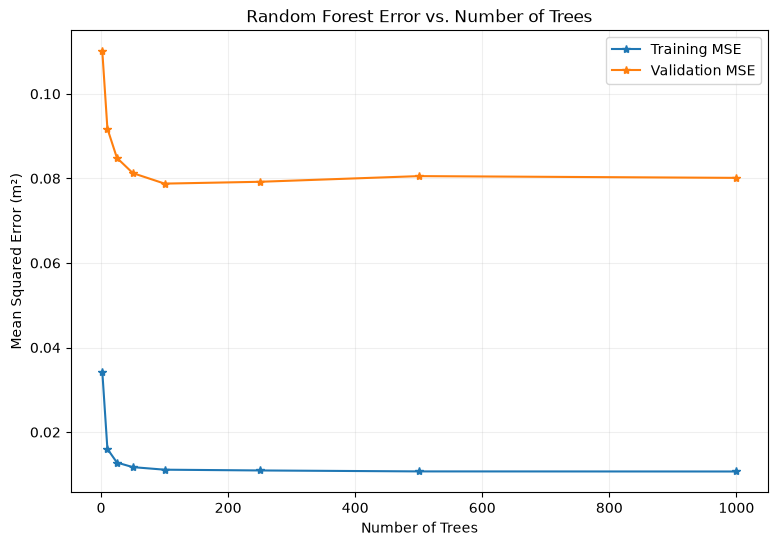

In [34]:
plt.figure(figsize=(9, 6))
plt.plot(forest_results['Number of Trees'],forest_results['Training MSE (m²)'],marker='*',label='Training MSE')
plt.plot(forest_results['Number of Trees'],forest_results['Validation MSE (m²)'],marker='*',label='Validation MSE')
plt.xlabel('Number of Trees')
plt.ylabel('Mean Squared Error (m²)')
plt.title('Random Forest Error vs. Number of Trees')
plt.legend()
plt.grid(alpha=0.2)
plt.show()